# Notebook 03: Data Overview, Sentiment, and Topics (Phase 3)

**Team:** Teenna Pachika and Johanna Garcia

This notebook creates the charts for the data, sentiment, and topic slides. Each chart is also saved as a PNG in the `figures/` folder.

## 1. Data Overview

In [1]:
# Set up
import sys
sys.path.append("..")

import os
import pandas as pd
import matplotlib.pyplot as plt
from src.preprocessing import load_reviews, get_negative

df = load_reviews()
neg = get_negative(df)

# Same colors as Notebook 01: red = negative, gray = neutral, green = positive
NEG_COLOR = "#B5544C"
STAR_COLORS = ["#B5544C", "#B5544C", "#BFBFBF", "#7A9E7E", "#7A9E7E"]

# Save each chart as a PNG for the slides
FIG_DIR = "../figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save_chart(name):
    """Save the current chart to the figures folder and show it."""
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

print(f"All reviews: {len(df):,} | Negative reviews (1-2 stars): {len(neg):,}")

All reviews: 50,000 | Negative reviews (1-2 stars): 4,147


### 1.1 The Data
50,000 Google Play reviews of Duolingo (US, English), July 29 to September 6, 2026. Usernames and profile images were removed for privacy.

| Column | What it means |
|---|---|
| `reviewId` | Unique ID for each review |
| `content` | Text of the review |
| `score` | Star rating, from 1 to 5 |
| `thumbsUpCount` | Number of users who marked the review as helpful |
| `reviewCreatedVersion` | App version the user had when writing the review (missing for about 8%) |
| `at` | Date and time the review was posted |

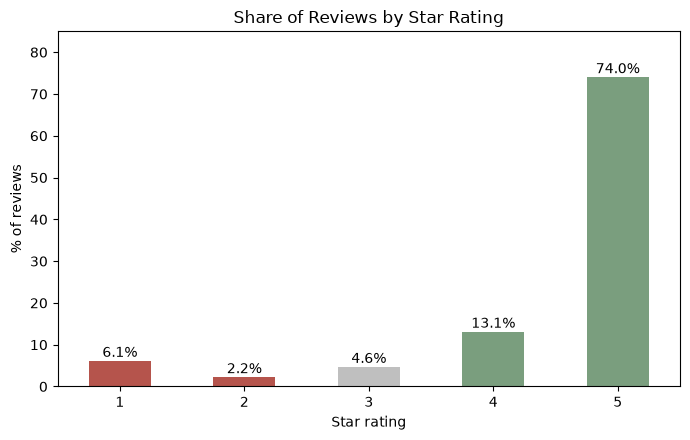

In [2]:
# Share of reviews for each star rating
pct = df["score"].value_counts(normalize=True).sort_index() * 100
ax = pct.plot(kind="bar", color=STAR_COLORS, figsize=(7, 4.5))
for i, v in enumerate(pct):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center")
plt.title("Share of Reviews by Star Rating")
plt.xlabel("Star rating")
plt.ylabel("% of reviews")
plt.xticks(rotation=0)
plt.ylim(0, 85)
save_chart("01_star_ratings")

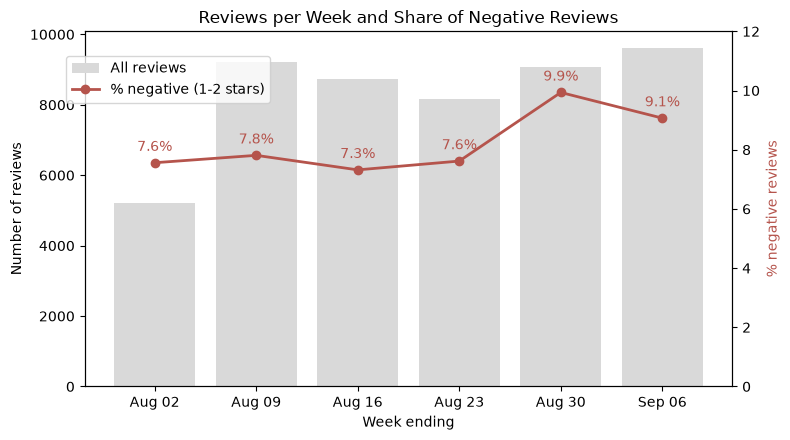

In [3]:
# Reviews per week and share of negative reviews (only one review after Sep 6, so we stop there)
weekly = df[df["at"] < "2026-09-07"].set_index("at").resample("W").agg(
    reviews=("score", "size"),
    neg_share=("score", lambda s: (s <= 2).mean() * 100),
)
labels = weekly.index.strftime("%b %d")

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.bar(labels, weekly["reviews"], color="#D9D9D9", label="All reviews")
ax1.set_xlabel("Week ending")
ax1.set_ylabel("Number of reviews")

ax2 = ax1.twinx()
ax2.plot(labels, weekly["neg_share"], color=NEG_COLOR, marker="o", linewidth=2, label="% negative (1-2 stars)")
ax2.set_ylabel("% negative reviews", color=NEG_COLOR)
ax2.set_ylim(0, 12)
for x, v in zip(labels, weekly["neg_share"]):
    ax2.text(x, v + 0.4, f"{v:.1f}%", ha="center", color=NEG_COLOR)

plt.title("Reviews per Week and Share of Negative Reviews")
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.88))
save_chart("02_reviews_over_time")

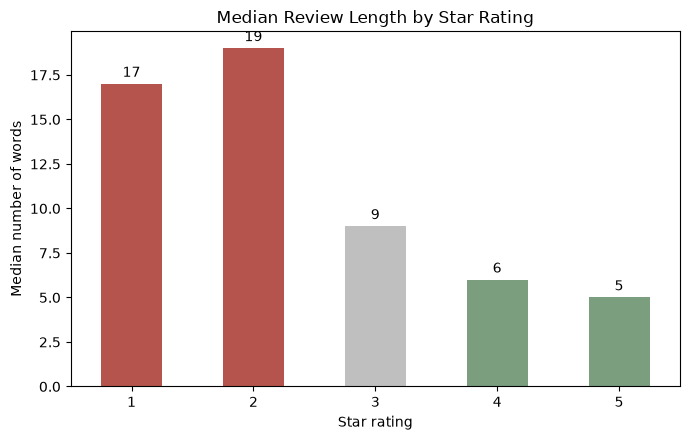

In [4]:
# Median review length for each star rating
med = df.groupby("score")["n_words"].median()
ax = med.plot(kind="bar", color=STAR_COLORS, figsize=(7, 4.5))
for i, v in enumerate(med):
    ax.text(i, v + 0.4, f"{v:.0f}", ha="center")
plt.title("Median Review Length by Star Rating")
plt.xlabel("Star rating")
plt.ylabel("Median number of words")
plt.xticks(rotation=0)
save_chart("03_length_by_stars")

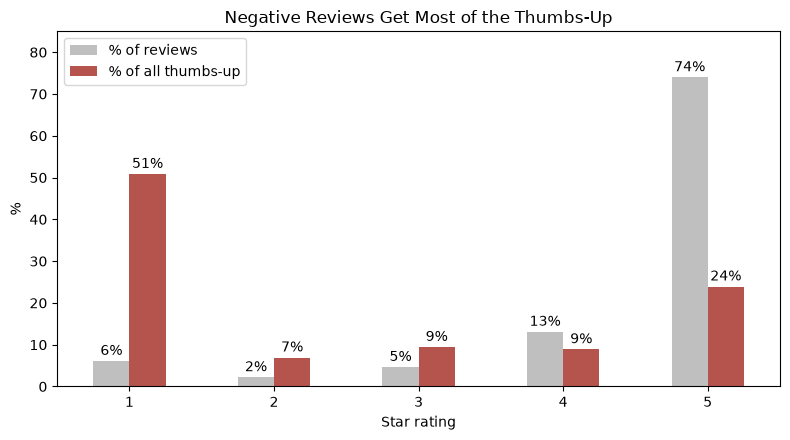

In [5]:
# Compare each star rating's share of reviews with its share of all thumbs-up
thumbs = pd.DataFrame({
    "% of reviews": df["score"].value_counts(normalize=True).sort_index() * 100,
    "% of all thumbs-up": df.groupby("score")["thumbsUpCount"].sum() / df["thumbsUpCount"].sum() * 100,
})
ax = thumbs.plot(kind="bar", color=["#BFBFBF", NEG_COLOR], figsize=(8, 4.5))
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.0f%%", padding=2)
plt.title("Negative Reviews Get Most of the Thumbs-Up")
plt.xlabel("Star rating")
plt.ylabel("%")
plt.xticks(rotation=0)
plt.ylim(0, 85)
save_chart("04_thumbs_up")

**What we see:** 74% of reviews are 5 stars, and only 8.3% are 1-2 stars. The share of negative reviews stayed around 7.5% for most of August, then jumped to 9.9% in the week ending Aug 30. Negative reviews are much longer (17-19 words vs. 5 for 5-star reviews). And even though 1-star reviews are only 6% of all reviews, they received 51% of all thumbs-up (45% even without the single most-liked review).

**What it means:** Unhappy users are few, but they explain their problems in detail, and other users agree with them. That makes negative reviews the best place to find what Duolingo should fix, especially around the late-August jump.

## 2. Sentiment by Star Rating
We score every review with VADER (from -1, very negative, to +1, very positive) and check whether the tone of the text matches the star rating.

In [6]:
from src.sentiment import add_sentiment

df = add_sentiment(df)
neg = get_negative(df)   # update neg so it includes the sentiment column

df.groupby("score")["sentiment"].mean().round(2)

score
1   -0.06
2    0.12
3    0.31
4    0.46
5    0.53
Name: sentiment, dtype: float64

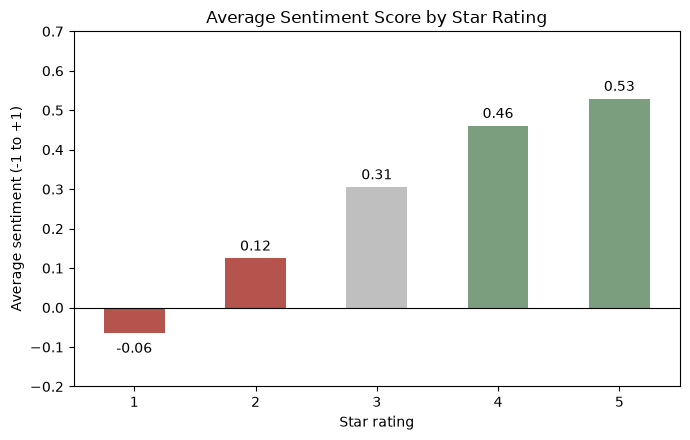

In [7]:
# Average sentiment score for each star rating
avg = df.groupby("score")["sentiment"].mean()
ax = avg.plot(kind="bar", color=STAR_COLORS, figsize=(7, 4.5))
for i, v in enumerate(avg):
    ax.text(i, v + (0.02 if v >= 0 else -0.05), f"{v:.2f}", ha="center")
ax.axhline(0, color="black", linewidth=0.8)
plt.title("Average Sentiment Score by Star Rating")
plt.xlabel("Star rating")
plt.ylabel("Average sentiment (-1 to +1)")
plt.xticks(rotation=0)
plt.ylim(-0.2, 0.7)
save_chart("05_sentiment_by_stars")

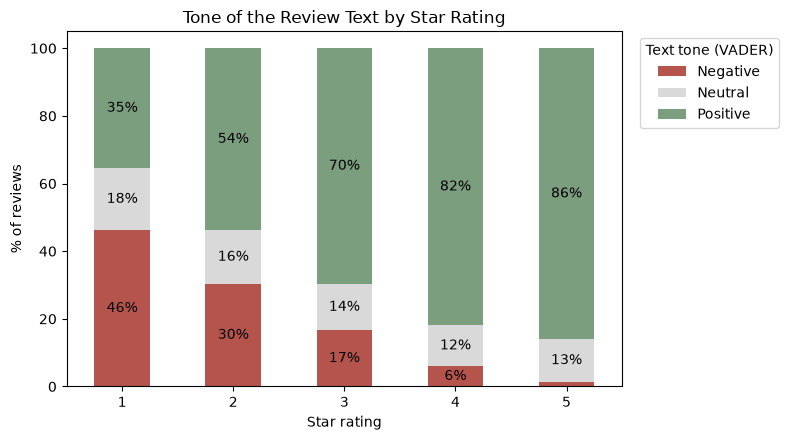

In [8]:
# Group each review's text as negative, neutral, or positive (standard VADER cutoffs: -0.05 and 0.05)
df["text_tone"] = pd.cut(df["sentiment"], bins=[-1.01, -0.05, 0.05, 1.01],
                         labels=["Negative", "Neutral", "Positive"])
tone = pd.crosstab(df["score"], df["text_tone"], normalize="index") * 100

ax = tone.plot(kind="bar", stacked=True, color=[NEG_COLOR, "#D9D9D9", "#7A9E7E"], figsize=(8, 4.5))
for bars in ax.containers:
    ax.bar_label(bars, labels=[f"{v:.0f}%" if v >= 4 else "" for v in bars.datavalues], label_type="center")
plt.title("Tone of the Review Text by Star Rating")
plt.xlabel("Star rating")
plt.ylabel("% of reviews")
plt.xticks(rotation=0)
plt.legend(title="Text tone (VADER)", bbox_to_anchor=(1.02, 1), loc="upper left")
save_chart("06_text_tone_by_stars")

**What we see:** Sentiment rises steadily with the star rating, from -0.06 for 1-star reviews to 0.53 for 5-star reviews, so the text and the stars mostly agree. But VADER isn't perfect: 46% of 1-star reviews read as negative, and 35% even read as positive.

**What it means:** Sentiment confirms that unhappy users write unhappy text, but it often misses complaints written with polite or positive words (for example, "I loved this app until the update"). That's why we use Claude and topic modeling to find *what* users complain about, not just *how* they feel.

## 3. Sentiment Over Time
Average sentiment per week, for all reviews and for negative reviews. Dashed lines mark app updates. Our data doesn't include release dates, so we estimate each one as the first day a new version got at least 20 reviews.

In [11]:
from src.app_versions import get_release_dates

release_dates = get_release_dates(df)
release_dates.dt.strftime("%b %d")

6.91    Aug 04
6.92    Aug 11
6.93    Aug 18
6.94    Aug 26
6.95    Sep 01
dtype: str

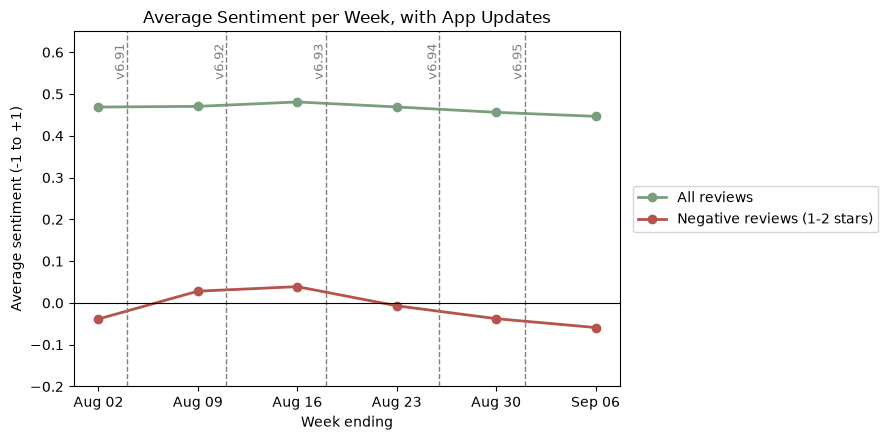

In [12]:
import matplotlib.dates as mdates

# Weekly average sentiment (we stop at Sep 6, since there's only one review after that)
recent = df[df["at"] < "2026-09-07"]
weekly_all = recent.set_index("at")["sentiment"].resample("W").mean()
weekly_neg = recent[recent["score"] <= 2].set_index("at")["sentiment"].resample("W").mean()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(weekly_all.index, weekly_all, marker="o", color="#7A9E7E", linewidth=2, label="All reviews")
ax.plot(weekly_neg.index, weekly_neg, marker="o", color=NEG_COLOR, linewidth=2, label="Negative reviews (1-2 stars)")

# Dashed line for each app update
for version, date in release_dates.items():
    ax.axvline(date, color="gray", linestyle="--", linewidth=1)
    ax.text(date, 0.62, f"v{version}", rotation=90, va="top", ha="right", fontsize=9, color="gray")

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(weekly_all.index)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
plt.title("Average Sentiment per Week, with App Updates")
plt.xlabel("Week ending")
plt.ylabel("Average sentiment (-1 to +1)")
plt.ylim(-0.2, 0.65)
plt.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
save_chart("07_sentiment_over_time")

**What we see:** Duolingo released a new version almost every week. Overall sentiment barely moved (about 0.45-0.48 every week). Negative reviews became a bit more negative after mid-August, dropping from 0.04 in the week ending Aug 16 to -0.06 in the week ending Sep 6, around versions 6.93-6.95. This is the same period when the share of negative reviews jumped from 7.6% to 9.9%.

**What it means:** Sentiment alone can't tell us which update caused the problem, but it points to late August as the time to look at. In the complaint charts, we check which complaint types grew in those same weeks.

## 4. Topic Modeling
We use the same NMF model as in Phase 2 (Notebook 02): TF-IDF on negative reviews with at least 5 words, extra stopwords for generic and opinion words, and 10 topics. Each review is assigned to the topic it matches best.

In [13]:
from src.topics import build_tfidf, show_topics, assign_topics

# Same extra stopwords as Notebook 02: generic, opinion, and filler words that hide the real complaints
extra_stopwords = [
    "duolingo", "app", "duo", "language", "languages", "learn", "learning", "english", "lesson", "lessons",
    "good", "bad", "best", "worst", "great", "love", "hate", "annoying", "irritating",
    "sucks", "ugly", "disgusting", "better", "worse",
    "like", "really", "just", "don", "doesn", "did", "didn", "ve", "got", "want", "know",
    "make", "makes", "use", "using", "say", "need", "think", "feel", "feels", "way", "thing",
    "time", "day", "people", "new", "used", "soo", "hai", "fun", "waste", "help", "experience",
]

long_neg = neg[neg["n_words"] >= 5].copy()
tfidf, T = build_tfidf(long_neg["content"], extra_stopwords=extra_stopwords)
nmf, topics = show_topics(tfidf, T, k=10, n_words=4)
long_neg["topic"] = assign_topics(nmf, T)

print(f"Negative reviews with 5+ words: {len(long_neg):,}")
topics

Negative reviews with 5+ words: 3,267


Topic 0           energy, hearts, pay, bring
Topic 1    iranian, test, students, decision
Topic 2                ads, ad, close, watch
Topic 3       chess, play, play chess, oscar
Topic 4           ai, slop, ai slop, garbage
Topic 5     free, trial, subscription, money
Topic 6      streak, days, lost, days streak
Topic 7         icon, changing, change, stop
Topic 8          words, update, teach, wrong
Topic 9         add, persian, urdu, add urdu
Name: top words, dtype: str

In [14]:
# Names we gave each topic in Notebook 02, after reading its top words
TOPIC_NAMES = {
    0: "Energy and hearts",
    1: "Iranian users and the English Test",
    2: "Ads",
    3: "Chess course",
    4: "AI-generated content",
    5: "Subscriptions and billing",
    6: "Lost streaks",
    7: "App icon changes",
    8: "Course content and updates",
    9: "Language requests",
}

long_neg["topic_name"] = long_neg["topic"].map(TOPIC_NAMES)

topic_summary = pd.DataFrame({
    "name": list(TOPIC_NAMES.values()),
    "top_words": topics.values,
    "reviews": long_neg["topic"].value_counts().sort_index().values,
})
topic_summary["pct"] = (topic_summary["reviews"] / topic_summary["reviews"].sum() * 100).round(1)
topic_summary.sort_values("reviews", ascending=False)

,name,top_words,reviews,pct
8,Course content and updates,"words, update, teach, wrong",1081,33.1
5,Subscriptions and billing,"free, trial, subscription, money",414,12.7
0,Energy and hearts,"energy, hearts, pay, bring",326,10.0
6,Lost streaks,"streak, days, lost, days streak",258,7.9
7,App icon changes,"icon, changing, change, stop",246,7.5
3,Chess course,"chess, play, play chess, oscar",221,6.8
4,AI-generated content,"ai, slop, ai slop, garbage",212,6.5
2,Ads,"ads, ad, close, watch",207,6.3
9,Language requests,"add, persian, urdu, add urdu",185,5.7
1,Iranian users and the English Test,"iranian, test, students, decision",117,3.6


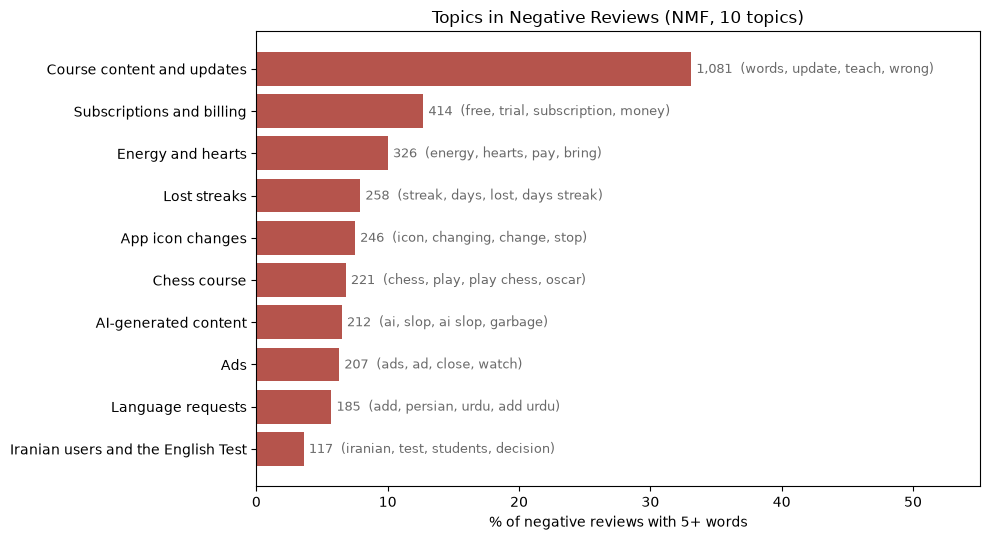

In [15]:
# Size of each topic, with its top words next to the bar
plot_data = topic_summary.sort_values("reviews")

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(plot_data["name"], plot_data["pct"], color=NEG_COLOR)
for bar, words, n in zip(bars, plot_data["top_words"], plot_data["reviews"]):
    ax.text(bar.get_width() + 0.4, bar.get_y() + bar.get_height() / 2,
            f"{n:,}  ({words})", va="center", fontsize=9, color="dimgray")
plt.title("Topics in Negative Reviews (NMF, 10 topics)")
plt.xlabel("% of negative reviews with 5+ words")
plt.xlim(0, plot_data["pct"].max() + 22)
save_chart("08_topics")

**What we see:** The largest topic is course content and updates (33% of negative reviews), a broad mix of complaints about lessons. After that come subscriptions and billing (13%), energy and hearts (10%), lost streaks (8%), and app icon changes (8%). The model also found smaller, very specific issues: the chess course, AI-generated content, ads, requests for new languages, and Iranian users blocked from the English Test.

**What it means:** Most specific complaints are about how Duolingo makes money and keeps users coming back (subscriptions, energy, streaks, and the app icon), not about the language content. Topic modeling is free and found themes we didn't expect, but each review gets only one topic, and the biggest topic is too broad. That's why we use Claude to label each review with one or more clear complaint types.